In [34]:
#imports
from pathlib import Path
from rapidocr import RapidOCR
from rapidocr.utils.output import RapidOCROutput
import cv2
import matplotlib.pyplot as plt
import numpy as np

## Helper Functions

In [ ]:
#load first 5 images from train path
train_path = Path("../images/train")

def is_image(file_path: Path) -> bool:
    img = cv2.imread(str(file_path))
    return img is not None and img.size > 0

photos: list[str] = []
for file_path in sorted(train_path.iterdir()):
    if not file_path.is_file() or not is_image(file_path):
        continue
    photos.append(str(file_path))
    if len(photos) == 1:
        break

print(photos)

['../images/train/001.jpg', '../images/train/002.jpg', '../images/train/003.jpg', '../images/train/004.jpg', '../images/train/005.jpg']


In [ ]:


def visualize_results(results):
    for res in results:
        fig, row = plt.subplots(1, 2, figsize=(10, 10), layout="constrained",
                                gridspec_kw=dict(width_ratios=[1, 2]))  # vis() output is wider with teh results

        row[0].imshow(res["org_img"])
        row[0].set_title(res["name"])
        row[1].imshow(res["ocr_img"])
        row[1].set_title(f"RapidOCR - {res['name']}")

        row[0].set_axis_off()
        row[1].set_axis_off()
        plt.show()

## 1 | RapidOCR

In [ ]:
engine = RapidOCR()

def run_ocr(img_path: str) -> RapidOCROutput | None:
    result = engine(img_path)
    if not isinstance(result, RapidOCROutput) or result.boxes is None:
        return None
    return result

rapid_results = []

for photo in photos: 
    result = run_ocr(photo)
    org_img = cv2.cvtColor(cv2.imread(photo), cv2.COLOR_BGR2RGB)  # cv2 loads BGR; matplotlib expects RGB

    if result is None: 
        continue

    vis_img = result.vis()  # BGR ndarray or None
    ocr_img = cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB) if vis_img is not None else org_img
    rapid_results.append(dict(
        name=Path(photo).name,
        text=result.txts or (), 
        scores=result.scores or (), 
        org_img=org_img,
        ocr_img=ocr_img, 
    ))

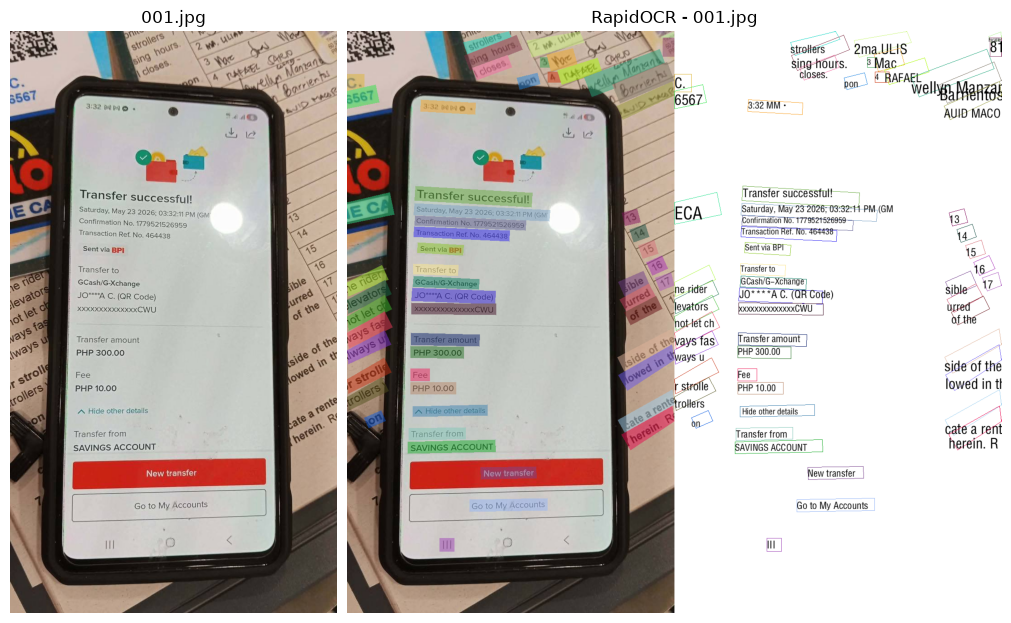

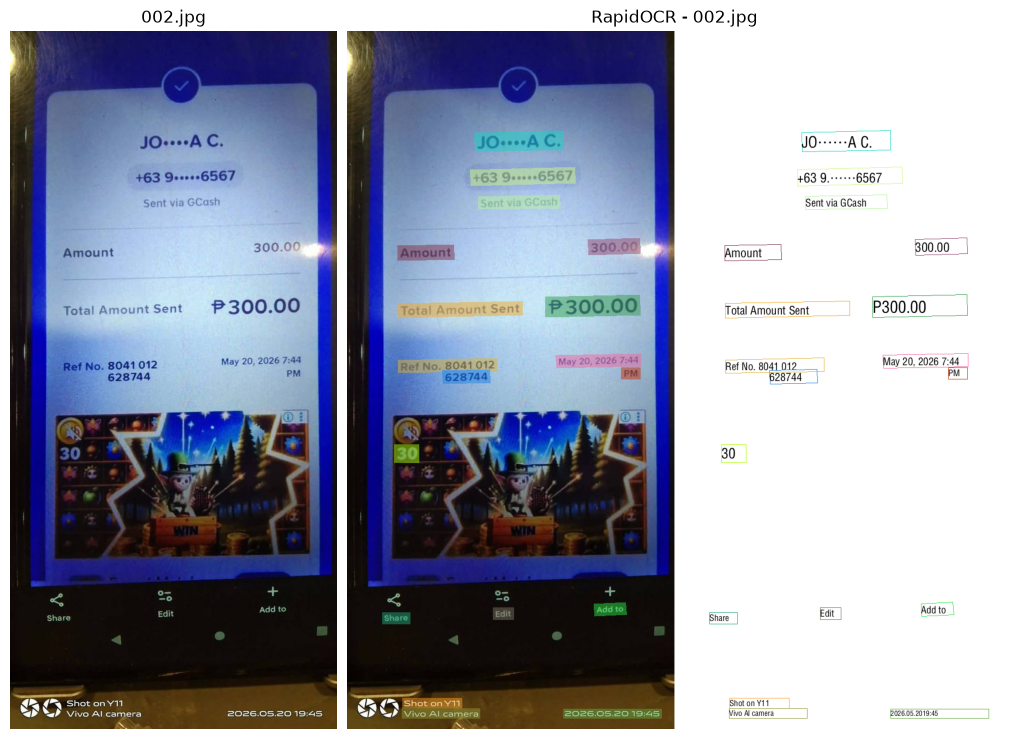

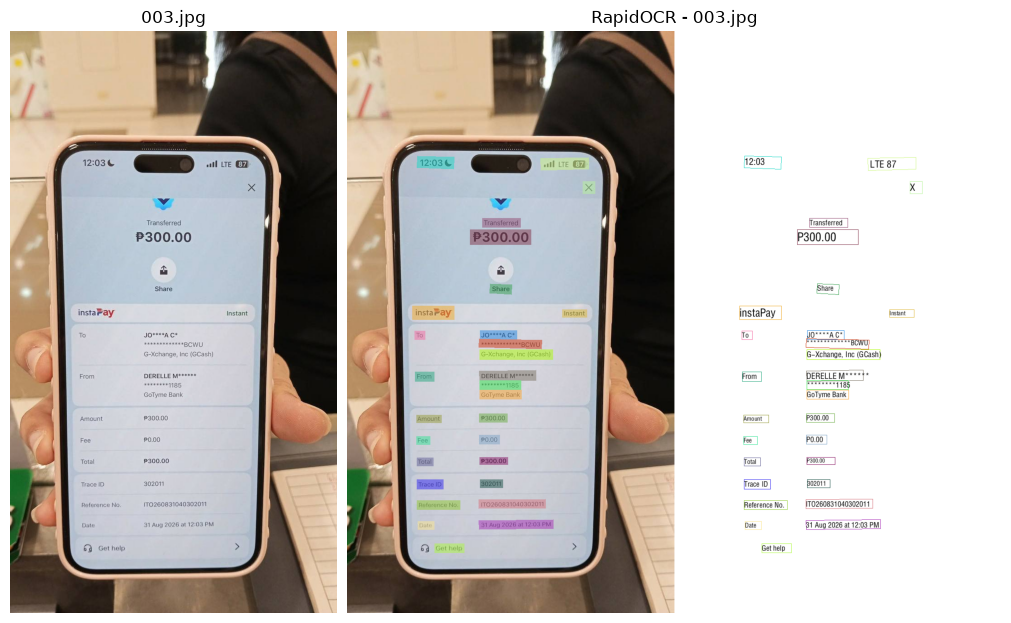

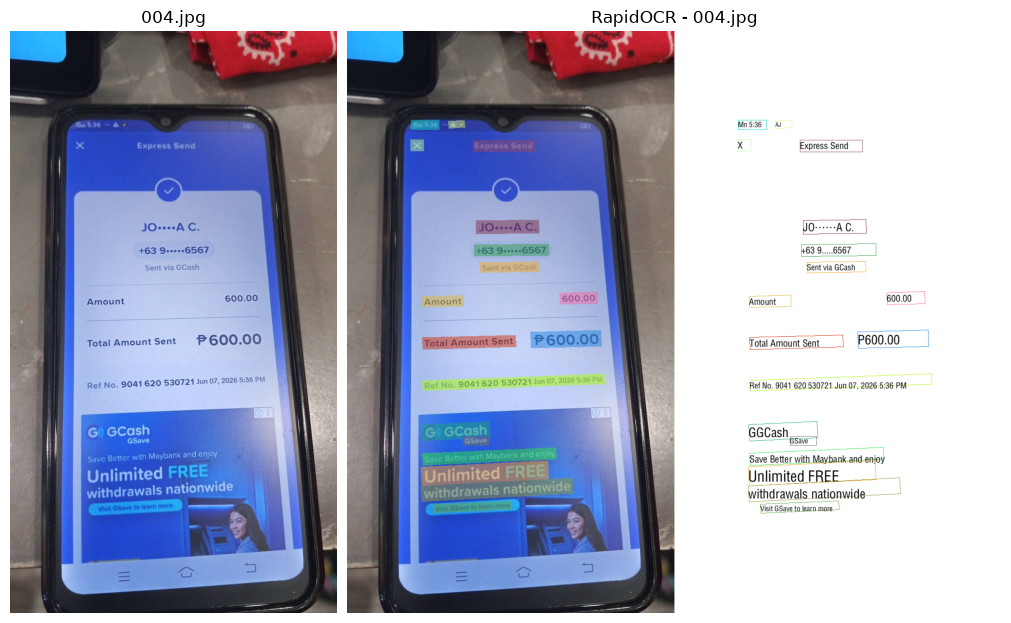

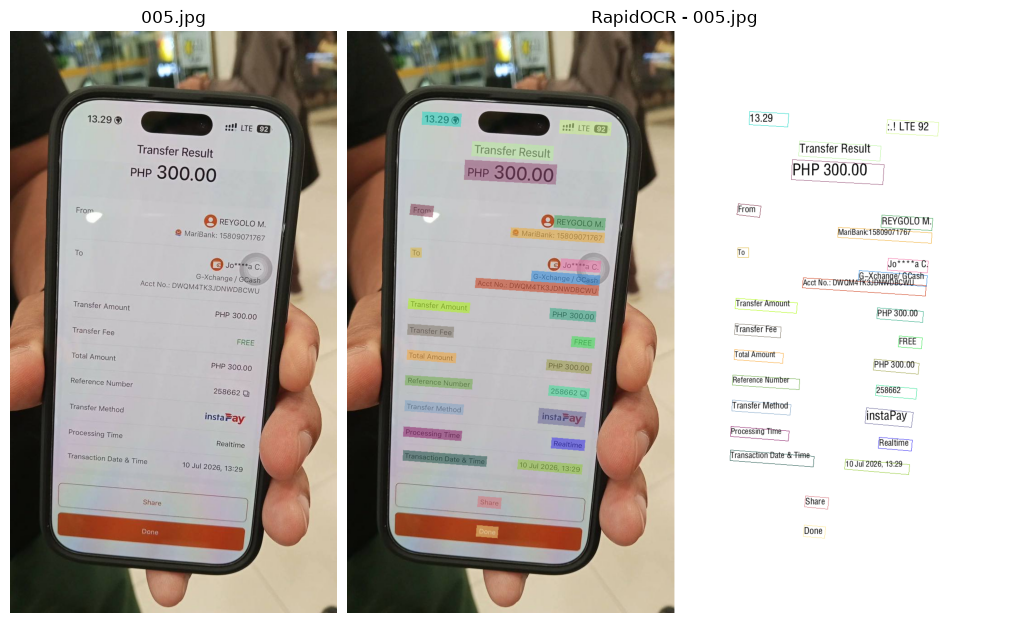

In [49]:
#For each pair of images and their results, I want a 1x2 subplot with the results printed below
visualize_results(rapid_results)

## 2 | PyTesseract